In [10]:
# Choose one: 'database' or 'csv'
DATA_SOURCE = 'database'

# Database settings are loaded from the project-root .env file.

In [11]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import text

# Locate the repository whether Jupyter starts at the root or notebook folder.
search_locations = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(path for path in search_locations if (path / 'README.md').exists())
sys.path.insert(0, str(PROJECT_ROOT))
from modelling.config import get_sqlalchemy_engine
CSV_PATH = PROJECT_ROOT / 'data' / 'processed' / 'US' / 'us_macro_2007_2023.csv'

print('Project root:', PROJECT_ROOT)
print('Selected source:', DATA_SOURCE)

Project root: d:\Master Semester 4\Thesis
Selected source: database


In [12]:
if DATA_SOURCE == 'database':
    engine = get_sqlalchemy_engine()

    query = text("""
        SELECT month_date, cpi_value, unemployment_rate,
               industrial_production_value, avg_monthly_sentiment
        FROM analytics.Monthly_Region_Wide_View
        WHERE region_code = 'US'
        ORDER BY month_date
    """)
    raw = pd.read_sql(query, engine, parse_dates=['month_date'])
    raw = raw.rename(columns={
        'month_date': 'Date',
        'cpi_value': 'CPI',
        'unemployment_rate': 'Unemployment',
        'industrial_production_value': 'Industrial_Production',
        'avg_monthly_sentiment': 'News_Sentiment',
    })
else:
    snapshot = pd.read_csv(CSV_PATH, parse_dates=['Date'])
    raw = snapshot.rename(columns={
        'CPIAUCSL': 'CPI',
        'UNRATE': 'Unemployment',
        'INDPRO': 'Industrial_Production',
    })[[
        'Date', 'CPI', 'Unemployment',
        'Industrial_Production', 'News_Sentiment'
    ]]

raw = raw.sort_values('Date').set_index('Date')
print('Rows:', len(raw))
print('Period:', raw.index.min().date(), 'to', raw.index.max().date())
raw.head()

Rows: 204
Period: 2007-01-01 to 2023-12-01


,CPI,Unemployment,Industrial_Production,News_Sentiment
Date,,,,
2007-01-01,203.437,4.6,99.8346,NaN
2007-02-01,204.226,4.5,100.7753,NaN
2007-03-01,205.288,4.4,100.9547,NaN
2007-04-01,205.904,4.5,101.6334,NaN
2007-05-01,206.755,4.4,101.7306,NaN


In [13]:
data = raw.copy()

# pct_change(1) compares with one month earlier.
data['Inflation_MoM'] = data['CPI'].pct_change(1, fill_method=None) * 100

# pct_change(12) compares with twelve months earlier.
data['Inflation_YoY'] = data['CPI'].pct_change(12, fill_method=None) * 100

# Industrial production is an index, so we also calculate its monthly change.
data['IP_Growth_MoM'] = data['Industrial_Production'].pct_change(1, fill_method=None) * 100

# We do not fill missing values with future observations.
data[['CPI', 'Inflation_MoM', 'Inflation_YoY']].head(14)

,CPI,Inflation_MoM,Inflation_YoY
Date,,,
2007-01-01,203.437,NaN,NaN
2007-02-01,204.226,0.387835,NaN
2007-03-01,205.288,0.520012,NaN
2007-04-01,205.904,0.300066,NaN
2007-05-01,206.755,0.413299,NaN
2007-06-01,207.234,0.231675,NaN
2007-07-01,207.603,0.178060,NaN
2007-08-01,207.667,0.030828,NaN
2007-09-01,208.547,0.423755,NaN


In [14]:
summary = pd.DataFrame({
    'Meaning': {
        'Inflation_MoM': 'Monthly CPI inflation — initial forecasting target',
        'Inflation_YoY': 'Annual inflation — useful for interpreting regimes',
        'Unemployment': 'Labour-market condition — possible predictor',
        'IP_Growth_MoM': 'Economic activity — possible predictor',
        'News_Sentiment': 'Monthly FinBERT score — later NLP predictor',
    },
    'Role': {
        'Inflation_MoM': 'Target',
        'Inflation_YoY': 'Interpretation / alternative target',
        'Unemployment': 'Possible input',
        'IP_Growth_MoM': 'Possible input',
        'News_Sentiment': 'Possible input',
    },
})
summary

,Meaning,Role
Inflation_MoM,Monthly CPI inflation — initial forecasting ta...,Target
Inflation_YoY,Annual inflation — useful for interpreting reg...,Interpretation / alternative target
Unemployment,Labour-market condition — possible predictor,Possible input
IP_Growth_MoM,Economic activity — possible predictor,Possible input
News_Sentiment,Monthly FinBERT score — later NLP predictor,Possible input


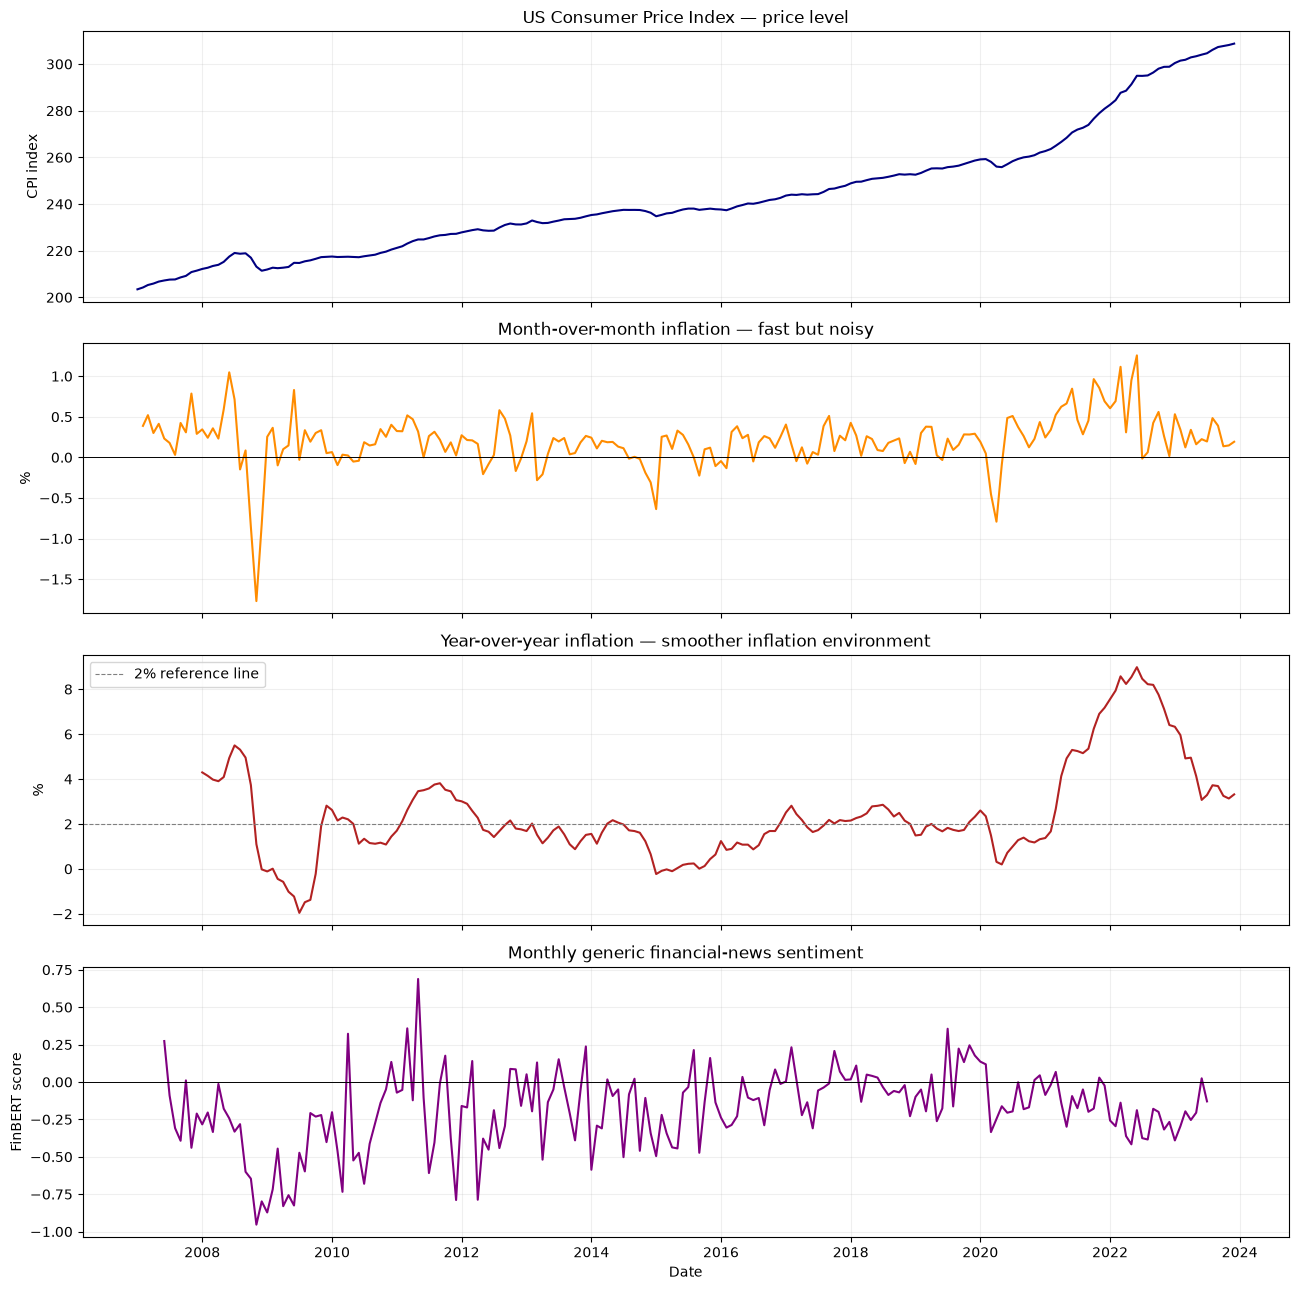

In [15]:
fig, axes = plt.subplots(4, 1, figsize=(13, 13), sharex=True)

axes[0].plot(data.index, data['CPI'], color='navy')
axes[0].set_title('US Consumer Price Index — price level')
axes[0].set_ylabel('CPI index')

axes[1].plot(data.index, data['Inflation_MoM'], color='darkorange')
axes[1].axhline(0, color='black', linewidth=0.7)
axes[1].set_title('Month-over-month inflation — fast but noisy')
axes[1].set_ylabel('%')

axes[2].plot(data.index, data['Inflation_YoY'], color='firebrick')
axes[2].axhline(2, color='gray', linestyle='--', linewidth=0.8, label='2% reference line')
axes[2].set_title('Year-over-year inflation — smoother inflation environment')
axes[2].set_ylabel('%')
axes[2].legend()

axes[3].plot(data.index, data['News_Sentiment'], color='purple')
axes[3].axhline(0, color='black', linewidth=0.7)
axes[3].set_title('Monthly generic financial-news sentiment')
axes[3].set_ylabel('FinBERT score')
axes[3].set_xlabel('Date')

for axis in axes:
    axis.grid(alpha=0.2)

plt.tight_layout()
plt.show()